In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error

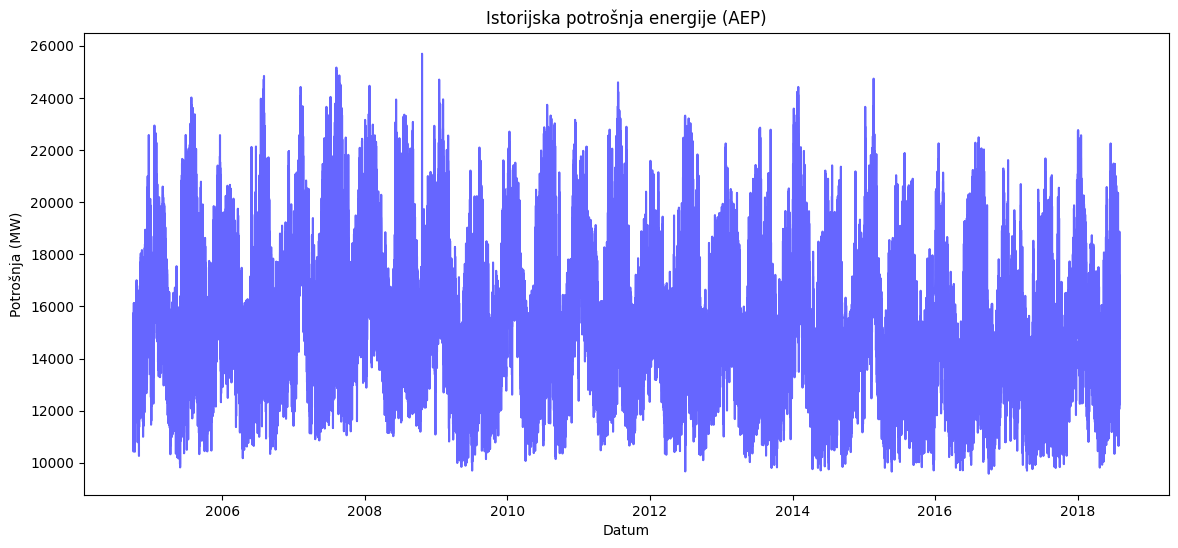

In [2]:
df = pd.read_csv("AEP_hourly.csv", parse_dates=['Datetime'])
df.set_index('Datetime', inplace=True)
df.sort_index(inplace=True)

# Vizuelizacija
plt.figure(figsize=(14, 6))
plt.plot(df['AEP_MW'], color='blue', alpha=0.6)
plt.title('Istorijska potrošnja energije (AEP)')
plt.xlabel('Datum')
plt.ylabel('Potrošnja (MW)')
plt.show()

ADF Statistika: -7.178034126643444
p-vrednost: 2.6950605310791083e-10
Podaci su stacionarni:


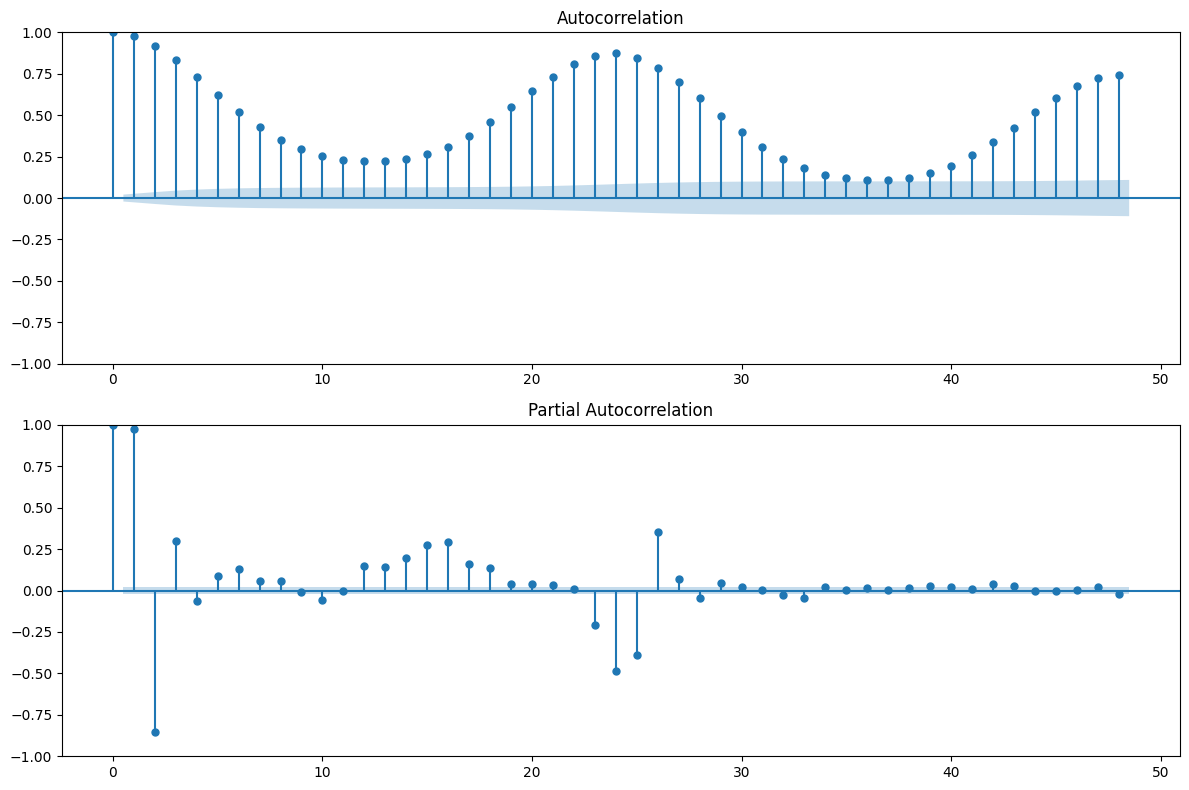

In [3]:
poslednji_datum = df.index.max()
start_datum = poslednji_datum - pd.Timedelta(days=365)
df_subset = df.loc[start_datum:poslednji_datum].copy()

# ADF test za proveru stacionarnosti
result = adfuller(df_subset['AEP_MW'])
print('ADF Statistika:', result[0])
print('p-vrednost:', result[1])
print('Podaci su stacionarni:' if result[1] < 0.05 else 'Podaci NISU stacionarni')

# Vizuelizacija
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(df_subset['AEP_MW'], lags=48, ax=ax1)
plot_pacf(df_subset['AEP_MW'], lags=48, ax=ax2, method='yw')
plt.tight_layout()
plt.show()

Na osnovu gore prikazanih grafikona možemo zaključiti sledeće:

*   **ACF** grafikon ima oblik blago opadajuće sinusoide, što sugeriše da
nemamo ***Moving average*** **q = 0**
*   **PACF** grafikon naglo opada nakon koraka 2, što ukazuje da nam je autoregresivni deo **p = 2**





In [4]:
poslednji_datum = df.index.max()
start_datum = poslednji_datum - pd.Timedelta(days=730)
df_subset = df.loc[start_datum:poslednji_datum].copy()

# Popunjavanje interpolacijom
df_subset = df_subset.resample('h').mean()
df_subset['AEP_MW'] = df_subset['AEP_MW'].ffill()

# Podela na Train i Test (2 godine train, 6 meseci test)
test_hours = 24 * 180
train = df_subset.iloc[:-test_hours]
test = df_subset.iloc[-test_hours:]

print(f"Train set veličina: {len(train)} sati")
print(f"Test set veličina: {len(test)} sati")

# Definisanje i treniranje SARIMA modela
model = SARIMAX(train['AEP_MW'],
                order=(2, 0, 0),
                seasonal_order=(1, 1, 0, 24),
                enforce_stationarity=False,
                enforce_invertibility=False)

sarima_result = model.fit(disp=False)


Train set veličina: 13201 sati
Test set veličina: 4320 sati


In [11]:
# Predikcija za ceo test period
predictions = sarima_result.get_forecast(steps=test_hours).summary_frame()

# Evaluacija modela
mae = mean_absolute_error(test['AEP_MW'], predictions['mean'])
rmse = np.sqrt(mean_squared_error(test['AEP_MW'], predictions['mean']))
mape = np.mean(np.abs((test['AEP_MW'] - predictions['mean']) / test['AEP_MW'])) * 100

print(f"MAE:  {mae:.2f} MW")
print(f"RMSE: {rmse:.2f} MW")
print(f"MAPE: {mape:.2f} %")

MAE:  2118.73 MW
RMSE: 2531.48 MW
MAPE: 15.32 %


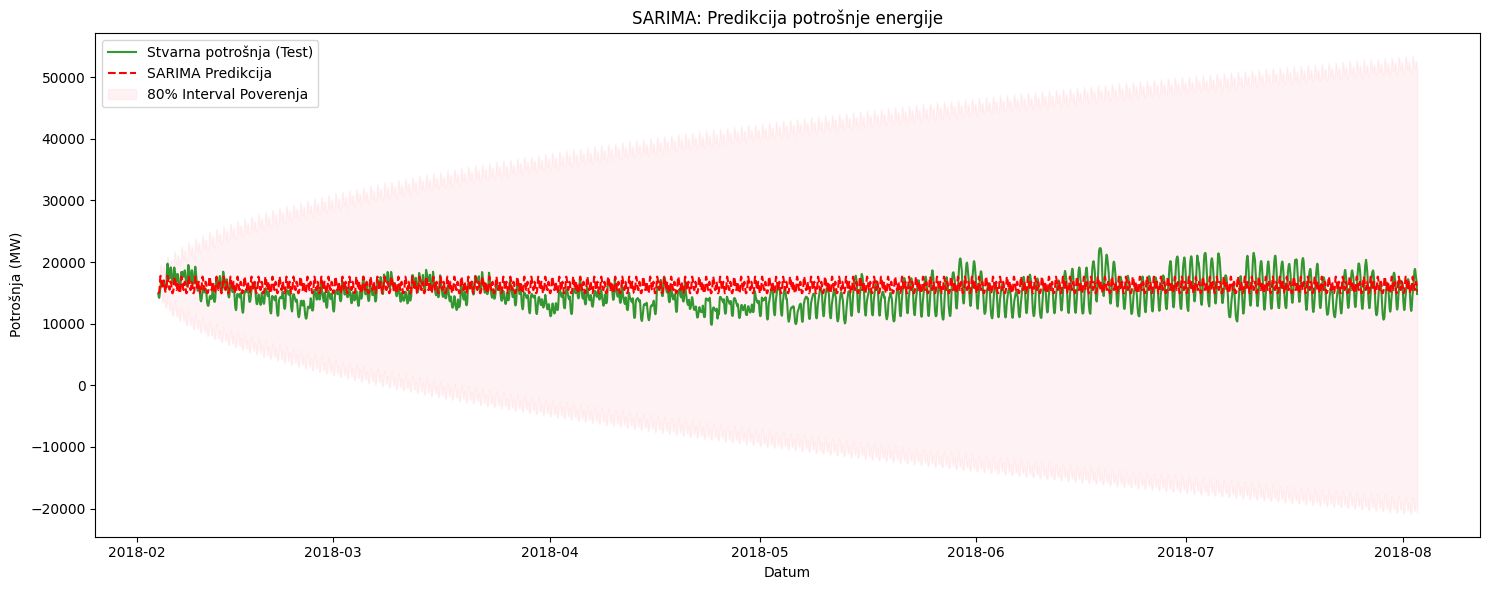

In [10]:
plt.figure(figsize=(15, 6))
plt.plot(test.index, test['AEP_MW'], label='Stvarna potrošnja (Test)', color='green', alpha=0.8)
plt.plot(test.index, predictions['mean'], label='SARIMA Predikcija', color='red', linestyle='--')
plt.fill_between(test.index, predictions['mean_ci_lower'], predictions['mean_ci_upper'], color='pink', alpha=0.2, label='80% Interval Poverenja')

plt.title('SARIMA: Predikcija potrošnje energije')
plt.xlabel('Datum')
plt.ylabel('Potrošnja (MW)')
plt.legend()
plt.tight_layout()
plt.show()